# HW3 sentiment classification

Train three fold-bagged uncased BERT models in Colab. Each encoder learns masked tokens on its own training fold before three epochs of sentiment fine-tuning. The notebook reports out-of-fold and held-out test macro-F1 and exports benchmark predictions.

In [6]:
%%bash
set -e
cd /content

if [ -d Intro_to_AI_HW/.git ]; then
    git -C Intro_to_AI_HW pull --ff-only origin main
else
    git clone --branch main https://github.com/billlllllllly/Intro_to_AI_HW.git
fi

cd Intro_to_AI_HW/IAI_HW3
pip install -r requirements.txt

Already up to date.


From https://github.com/billlllllllly/Intro_to_AI_HW
 * branch            main       -> FETCH_HEAD


In [7]:
%cd /content/Intro_to_AI_HW/IAI_HW3
import torch
from runpy import run_path

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab before training.")

run_bagged = run_path('fold_training.py')['run_bagged']
predictions, histories = run_bagged(
    checkpoint_dir='/content/hw3_fold_checkpoints',
    review_path='/content/neutral_errors.csv',
    epochs=3, mlm_epochs=2, head_lr=1.5e-4, layer_decay=0.9, smoothing=0.1,
)

/content/Intro_to_AI_HW/IAI_HW3
Development: 8105, held-out test: 895
fold_1: 5404 training, 2701 out-of-fold


Some weights of the model checkpoint at google-bert/bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


MLM epoch 1: masked-token loss 3.2540
MLM epoch 2: masked-token loss 2.8884
fold_1 epoch 1: train F1 0.6898, fold F1 0.8635
fold_1 epoch 2: train F1 0.8867, fold F1 0.8696
fold_1 epoch 3: train F1 0.9162, fold F1 0.8787
fold_2: 5396 training, 2709 out-of-fold


Some weights of the model checkpoint at google-bert/bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


MLM epoch 1: masked-token loss 3.2494
MLM epoch 2: masked-token loss 2.9019
fold_2 epoch 1: train F1 0.7107, fold F1 0.8531
fold_2 epoch 2: train F1 0.8925, fold F1 0.8760
fold_2 epoch 3: train F1 0.9167, fold F1 0.8764
fold_3: 5410 training, 2695 out-of-fold


Some weights of the model checkpoint at google-bert/bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


MLM epoch 1: masked-token loss 3.2310
MLM epoch 2: masked-token loss 2.8836
fold_3 epoch 1: train F1 0.7043, fold F1 0.8578
fold_3 epoch 2: train F1 0.8877, fold F1 0.8777
fold_3 epoch 3: train F1 0.9170, fold F1 0.8838
Raw OOF macro-F1 0.8797
Cross-calibrated OOF macro-F1 0.8830
Raw held-out ensemble macro-F1 0.8676
Calibrated held-out ensemble macro-F1 0.8690
OOF logit offsets {'negative': np.float64(0.0), 'neutral': np.float64(0.1), 'positive': np.float64(-0.1)}
              precision    recall  f1-score   support

    negative     0.9582    0.9525    0.9554      5710
     neutral     0.8002    0.7916    0.7958      1209
    positive     0.8808    0.9157    0.8979      1186

    accuracy                         0.9231      8105
   macro avg     0.8797    0.8866    0.8830      8105
weighted avg     0.9233    0.9231    0.9232      8105

[[5439  188   83]
 [ 188  957   64]
 [  49   51 1086]]


In [8]:
import pandas as pd

errors = pd.read_csv('/content/neutral_errors.csv')
print('Cross-calibrated out-of-fold errors by direction')
display(errors.groupby(['label', 'prediction']).size().rename('count').to_frame())
display(errors.groupby('label', group_keys=False).head(10))

Cross-calibrated out-of-fold errors by direction


,,count
label,prediction,
negative,neutral,188
neutral,negative,188


,id,text,label,prediction,p_neutral
0,25,@united a rapid trip plane ticket from Idaho t...,negative,neutral,0.604317
1,63,@USAirways on flight # 556 delayed#connection ...,negative,neutral,0.485000
2,69,@United give me a direct number I can call reg...,negative,neutral,0.484330
3,183,"@united I tried. We were hung up on, twice. ...",neutral,negative,0.076057
4,206,"@united Supposedly, they're out for delivery. ...",negative,neutral,0.703522
5,266,@SouthwestAir can you make a premium wifi that...,negative,neutral,0.857316
6,274,@USAirways @rylietolbert15 wow you wouldn't say,negative,neutral,0.442724
7,315,@USAirways I'm shutting my data off for the fl...,neutral,negative,0.042013
8,322,@jetblue the man sitting next 2 me at the term...,neutral,negative,0.246758
9,368,@AmericanAir Still looking as we speak.,neutral,negative,0.143055


In [9]:
from google.colab import files

output_path = "/content/predictions.csv"
predictions.to_csv(output_path, index=False)
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

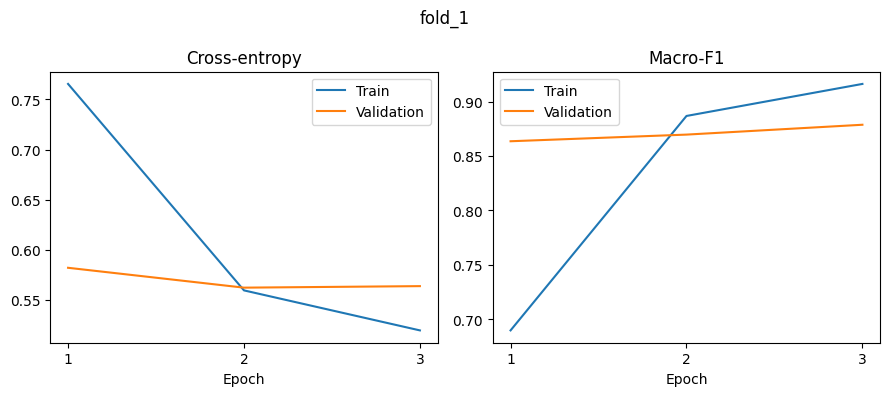

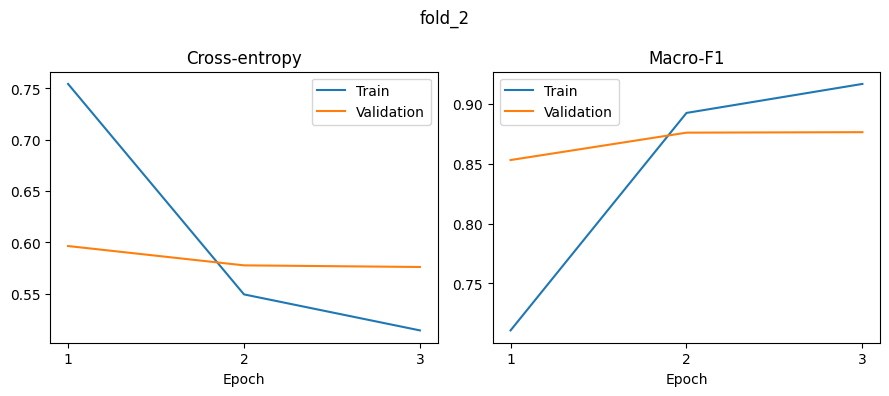

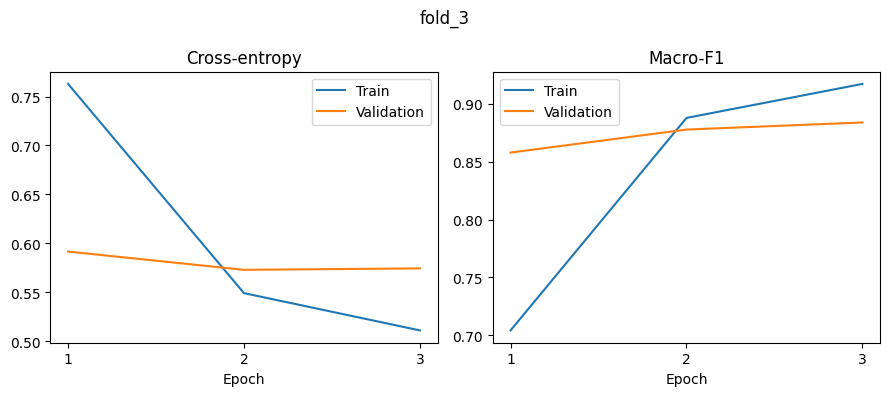

In [10]:
import matplotlib.pyplot as plt

for name, history in histories.items():
    epochs = range(1, len(history) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(9, 4))
    figure.suptitle(name)
    for index, title in enumerate(("Cross-entropy", "Macro-F1")):
        axes[index].plot(epochs, [train[index] for train, _ in history], label="Train")
        axes[index].plot(epochs, [val[index] for _, val in history], label="Validation")
        axes[index].set(xlabel="Epoch", title=title, xticks=list(epochs))
        axes[index].legend()
    figure.tight_layout()
    plt.show()